# Projet : Python • PostgreSQL • Power BI
Les équipes d’audit disposent d’une capacité de vérification limitée à 10 % du volume total des dossiers. L’objectif de
ce projet est de remplacer la sélection aléatoire ou manuelle par un modèle prédictif capable d’ordonner les dossiers
selon leur probabilité de non-conformité, afin de maximiser le nombre d’anomalies financières détectées sous cette
contrainte stricte de ressources. 

In [1]:
# Chargement du dataset UCI (id=475)
import pandas as pd
import hashlib

def compute_md5(filename):
    """Calcule l'empreinte MD5 d'une fichier par verrouillage de version."""
    with open(filename,"rb") as f:
        return hashlib.md5(f.read()).hexdigest()


# Inspecter et charger les data train et test
try :
    df_audit = pd.read_csv("C:/Users/skona/Documents/ProjetsData/risk_priorization/audit_data/audit_risk.csv")
    df_trial = pd.read_csv("C:/Users/skona/Documents/ProjetsData/risk_priorization/audit_data/trial.csv")

    print("Inspection des fichiers originaux : \n")
    print(f"df_audit : {df_audit.shape[0]} lignes et {df_audit.shape[1]} colonnes \n")
    print(f"df_trial : {df_trial.shape[0]} lignes et {df_trial.shape[1]} colonnes \n")

    print("Empreinte numérique : \n")
    print(f"df_audit : {compute_md5('C:/Users/skona/Documents/ProjetsData/risk_priorization/audit_data/audit_risk.csv')} \n")
    print(f"df_trial : {compute_md5('C:/Users/skona/Documents/ProjetsData/risk_priorization/audit_data/trial.csv')} \n")

except FileNotFoundError as e:
    print(f"Erreur, rassurez-vous de placer les données dans le bon dossier svp : ({e}) \n")
    


Inspection des fichiers originaux : 

df_audit : 776 lignes et 27 colonnes 

df_trial : 776 lignes et 18 colonnes 

Empreinte numérique : 

df_audit : 604aa8e6f089b24beca32851d1de6c2f 

df_trial : a78e6a078be7954585dcc3cef143c5ba 



In [2]:
print(f"Colonnes df_audit : {df_audit.columns.to_list()}")
print(f"Colonnes df_trial : {df_trial.columns.to_list()}")

Colonnes df_audit : ['Sector_score', 'LOCATION_ID', 'PARA_A', 'Score_A', 'Risk_A', 'PARA_B', 'Score_B', 'Risk_B', 'TOTAL', 'numbers', 'Score_B.1', 'Risk_C', 'Money_Value', 'Score_MV', 'Risk_D', 'District_Loss', 'PROB', 'RiSk_E', 'History', 'Prob', 'Risk_F', 'Score', 'Inherent_Risk', 'CONTROL_RISK', 'Detection_Risk', 'Audit_Risk', 'Risk']
Colonnes df_trial : ['Sector_score', 'LOCATION_ID', 'PARA_A', 'SCORE_A', 'PARA_B', 'SCORE_B', 'TOTAL', 'numbers', 'Marks', 'Money_Value', 'MONEY_Marks', 'District', 'Loss', 'LOSS_SCORE', 'History', 'History_score', 'Score', 'Risk']


In [3]:
print("Appercu du contenu de df_audit : ")
df_audit.head()

Appercu du contenu de df_audit : 


,Sector_score,LOCATION_ID,PARA_A,Score_A,Risk_A,PARA_B,Score_B,Risk_B,TOTAL,numbers,...,RiSk_E,History,Prob,Risk_F,Score,Inherent_Risk,CONTROL_RISK,Detection_Risk,Audit_Risk,Risk
0,3.89,23,4.18,0.6,2.508,2.50,0.2,0.500,6.68,5.0,...,0.4,0,0.2,0.0,2.4,8.574,0.4,0.5,1.7148,1
1,3.89,6,0.00,0.2,0.000,4.83,0.2,0.966,4.83,5.0,...,0.4,0,0.2,0.0,2.0,2.554,0.4,0.5,0.5108,0
2,3.89,6,0.51,0.2,0.102,0.23,0.2,0.046,0.74,5.0,...,0.4,0,0.2,0.0,2.0,1.548,0.4,0.5,0.3096,0
3,3.89,6,0.00,0.2,0.000,10.80,0.6,6.480,10.80,6.0,...,0.4,0,0.2,0.0,4.4,17.530,0.4,0.5,3.5060,1
4,3.89,6,0.00,0.2,0.000,0.08,0.2,0.016,0.08,5.0,...,0.4,0,0.2,0.0,2.0,1.416,0.4,0.5,0.2832,0


In [4]:
df_trial.head()

,Sector_score,LOCATION_ID,PARA_A,SCORE_A,PARA_B,SCORE_B,TOTAL,numbers,Marks,Money_Value,MONEY_Marks,District,Loss,LOSS_SCORE,History,History_score,Score,Risk
0,3.89,23,4.18,6,2.50,2,6.68,5.0,2,3.38,2,2,0,2,0,2,2.4,1
1,3.89,6,0.00,2,4.83,2,4.83,5.0,2,0.94,2,2,0,2,0,2,2.0,0
2,3.89,6,0.51,2,0.23,2,0.74,5.0,2,0.00,2,2,0,2,0,2,2.0,0
3,3.89,6,0.00,2,10.80,6,10.80,6.0,6,11.75,6,2,0,2,0,2,4.4,1
4,3.89,6,0.00,2,0.08,2,0.08,5.0,2,0.00,2,2,0,2,0,2,2.0,0


In [5]:
print("df_audit : NA par colonnes : ")
df_audit.isna().sum().sort_values(ascending=False)


df_audit : NA par colonnes : 


Money_Value       1
LOCATION_ID       0
Sector_score      0
Score_A           0
Risk_A            0
PARA_B            0
Score_B           0
Risk_B            0
TOTAL             0
numbers           0
PARA_A            0
Score_B.1         0
Risk_C            0
Score_MV          0
Risk_D            0
District_Loss     0
PROB              0
RiSk_E            0
History           0
Prob              0
Risk_F            0
Score             0
Inherent_Risk     0
CONTROL_RISK      0
Detection_Risk    0
Audit_Risk        0
Risk              0
dtype: int64

In [6]:
print("df_trial : NA par colonnes :")
df_trial.isna().sum().sort_values(ascending=False)

df_trial : NA par colonnes :


Money_Value      1
Sector_score     0
LOCATION_ID      0
PARA_A           0
PARA_B           0
SCORE_A          0
SCORE_B          0
TOTAL            0
numbers          0
Marks            0
MONEY_Marks      0
District         0
Loss             0
LOSS_SCORE       0
History          0
History_score    0
Score            0
Risk             0
dtype: int64

In [7]:
print(f"df_audit : nombre d'observations en doublons : {df_audit.duplicated().sum()}")
print(f"df_trial : nombre d'observations en doublons : {df_trial.duplicated().sum()}")


df_audit : nombre d'observations en doublons : 13
df_trial : nombre d'observations en doublons : 13


In [10]:
# Rapport automatique
def data_quality(df : pd.DataFrame) -> pd.DataFrame :
    return pd.DataFrame({
        "column":df.columns,
        "dtype": df.dtypes.astype(str).to_numpy(),
        "missing_n":df.isna().sum().to_numpy(),
        "missing_pct": (100 * df.isna().mean()).round(2).to_numpy(),
        "distinct_n": df.nunique(dropna=True).to_numpy(),
    })

report = data_quality(df_audit)
report.to_csv("C:/Users/skona/Documents/ProjetsData/risk_priorization/artifacts/df_audit_quality_columns.csv", index=False)

# Préparation et pipelines reproductibles

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

col_a_exclure = ["LOCATION_ID", "Score",'Risk_A', 'Risk_B', 'Risk_C', 'Risk_D', 'RiSk_E', 'Risk_F', 'Inherent_Risk', 
                 'CONTROL_RISK', 'Detection_Risk', 'Audit_Risk', 'Score_A', 'Score_B','Score_B.1', 'Score_MV']

# Nous décidons d'extraire ces variables car elles sont dérivées d'autres variables déjà disponible dans le dataset

numeriq = [col for col in df_audit.columns if col not in col_a_exclure]

# Variables explicatives
df_audit = df_audit[numeriq]


df_audit.corr()

,Sector_score,PARA_A,PARA_B,TOTAL,numbers,Money_Value,District_Loss,PROB,History,Prob,Risk
Sector_score,1.000000,-0.216824,-0.132670,-0.153316,-0.151840,-0.117589,-0.108202,-0.086750,-0.114798,-0.136900,-0.394131
PARA_A,-0.216824,1.000000,0.161940,0.267042,0.133786,0.449318,0.127804,0.043707,0.118279,0.172635,0.378758
PARA_B,-0.132670,0.161940,1.000000,0.994100,0.209855,0.125033,0.082944,0.042551,0.203582,0.316541,0.257029
TOTAL,-0.153316,0.267042,0.994100,1.000000,0.217641,0.168669,0.093342,0.046471,0.210752,0.326396,0.292022
numbers,-0.151840,0.133786,0.209855,0.217641,1.000000,0.186188,0.125010,0.035807,0.202327,0.209598,0.308141
Money_Value,-0.117589,0.449318,0.125033,0.168669,0.186188,1.000000,0.028231,0.031781,0.080080,0.112184,0.256992
District_Loss,-0.108202,0.127804,0.082944,0.093342,0.125010,0.028231,1.000000,0.055304,0.069379,0.083922,0.403806
PROB,-0.086750,0.043707,0.042551,0.046471,0.035807,0.031781,0.055304,1.000000,0.110063,0.141471,0.176912
History,-0.114798,0.118279,0.203582,0.210752,0.202327,0.080080,0.069379,0.110063,1.000000,0.859296,0.239453
Prob,-0.136900,0.172635,0.316541,0.326396,0.209598,0.112184,0.083922,0.141471,0.859296,1.000000,0.298639


In [12]:
# Nous allons aussi extraire la variable :
# - TOTAL car elle est fortment corrélée avec la variablePARA_B
# - Prob car elle est fortement corrélées à History
col_a_exclure = ["TOTAL", "Prob"]
numeriq = [col for col in df_audit.columns if col not in col_a_exclure]

df_audit = df_audit[numeriq]
df_audit.columns

Index(['Sector_score', 'PARA_A', 'PARA_B', 'numbers', 'Money_Value',
       'District_Loss', 'PROB', 'History', 'Risk'],
      dtype='object')

In [13]:
# Variable cible
Y = df_audit["Risk"]

# Variables explicatives
X = df_audit.drop(columns="Risk")

# Pipeline
numerPipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

numeriq = numeriq[0:8] 

preprocess = ColumnTransformer([("num",numerPipeline,numeriq)])

pipe = Pipeline([
    ("prep",preprocess),
    ("modl", LogisticRegression(max_iter=2000,random_state=42)),
     ])


# Split
x_train, x_test, y_train, y_test = train_test_split(X,Y, test_size = 0.2, random_state= 42)


{'whiskers': [<matplotlib.lines.Line2D at 0x23b7664ef90>,
 'caps': [<matplotlib.lines.Line2D at 0x23b76658a50>,
 'boxes': [<matplotlib.lines.Line2D at 0x23b76645110>],
 'medians': [<matplotlib.lines.Line2D at 0x23b7665a250>],
 'fliers': [<matplotlib.lines.Line2D at 0x23b7665ae50>],
 'means': []}

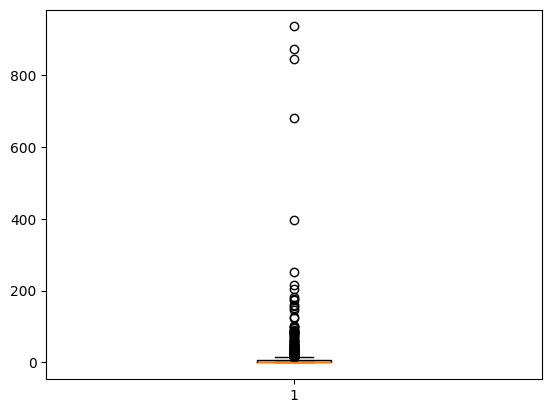

In [14]:
import matplotlib.pyplot as plt
plt.boxplot(df_audit["Money_Value"].dropna())

# Ingestion PostgreSQL et Benchmarking (3 modèles)

In [15]:
import numpy as np
from sqlalchemy import create_engine
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [16]:
# ÉTAPE 1 : CHARGEMENT ET INSERTION DANS LA TABLE 'raw_audits'

chemin_csv = "C:/Users/skona/Documents/ProjetsData/risk_priorization/audit_data/audit_risk.csv"
df = pd.read_csv(chemin_csv)
df.columns = df.columns.str.strip() # Nettoyage des espaces éventuels

# Préparer le DataFrame exact correspondant aux colonnes de la table PostgreSQL
df_raw_sql = pd.DataFrame({
    "audit_id": range(1, len(df) + 1), # Identifiant unique 1 à 777
    "location_id": df["LOCATION_ID"].astype(str),
    "sector_score": df["Sector_score"],
    "para_a": df["PARA_A"],
    "para_b": df["PARA_B"],
    "total": df["TOTAL"],
    "numbers": df["numbers"],
    "money_value": df["Money_Value"],
    "district_loss": df["District_Loss"],
    "prob_district": df["PROB"],
    "history": df["History"],
    "prob_history": df["Prob"],
    "risk_target": df["Risk"]
})

In [ ]:
# Connexion à PostgreSQL (Modifiez le mot de passe et le port si nécessaire)
DB_USER = "postgres"
DB_PASS = "......"
DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "Risk_Scoring"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

# Insertion dans raw_audits (if_exists='append' conserve la structure et les contraintes SQL)
df_raw_sql.to_sql("raw_audits",engine, if_exists="append", index=False)
print(f"Succès : {len(df_raw_sql)} dossiers insérés dans 'raw_audits'.")

In [ ]:
# ==============================================================================
# ÉTAPE 2 : BENCHMARKING DE 3 MODÈLES (VALIDATION CROISÉE OUT-OF-FOLD)
# ==============================================================================
# Sélection stricte des 8 variables sans fuite de données ni colinéarité
features = ["Sector_score", "PARA_A", "PARA_B", "numbers", "Money_Value", "District_Loss", "PROB", "History"]
X = df[features].copy()
y = df["Risk"].values


# Définition des 3 modèles à comparer
modeles = {
    "LogisticRegression": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, random_state=42))
    ]),

    "RandomForest" : Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("rdf", RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=5, random_state=42))
    ]),

    "GrandientBoosting": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("gdb", GradientBoostingClassifier(n_estimators=150, max_depth=3, learning_rate=0.5, random_state=42))
    ])
    }



# Validation croisée stratifiée en 5 plis
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

liste_predictions_sql = []

for nom_modele, pipeline in modeles.items():
    # Calcul des probabilités Out-Of-Fold sur les 777 dossiers sans fuite de données
    probas_oof = cross_val_predict(pipeline, X, y, cv=cv, method="predict_proba")[:, 1]
    
    df_pred = pd.DataFrame({
        "audit_id": df_raw_sql["audit_id"],
        "model_name": nom_modele,
        "proba_risque": np.round(probas_oof, 6),
        "evaluation_type": "OOF_5Fold_CV"
    })
    liste_predictions_sql.append(df_pred)
    print(f"Modèle '{nom_modele}' évalué sur les {len(df_pred)} dossiers.")


# ÉTAPE 3 : INSERTION DES PRÉDICTIONS DANS 'model_predictions'
df_all_preds = pd.concat(liste_predictions_sql, ignore_index=True)
df_all_preds.to_sql("model_predictions", engine, if_exists = "append", index= False)
print(f"Succès : {len(df_all_preds)} prédictions (3 modèles x {len(df_raw_sql)} dossiers) insérées dans 'model_predictions' !")